In [1]:
import spectral as sp
import numpy as np
import matplotlib.pyplot as plt

# Path to one sample
hdr_file = "tomato_leaf/0dai_2hr_swir_bc_run1.bil.hdr"

# Open hyperspectral image
img = sp.open_image(hdr_file)

# Convert to numpy array
data = img.load()
print("Shape:", data.shape)  # (lines, samples, bands)


Shape: (559, 320, 168)


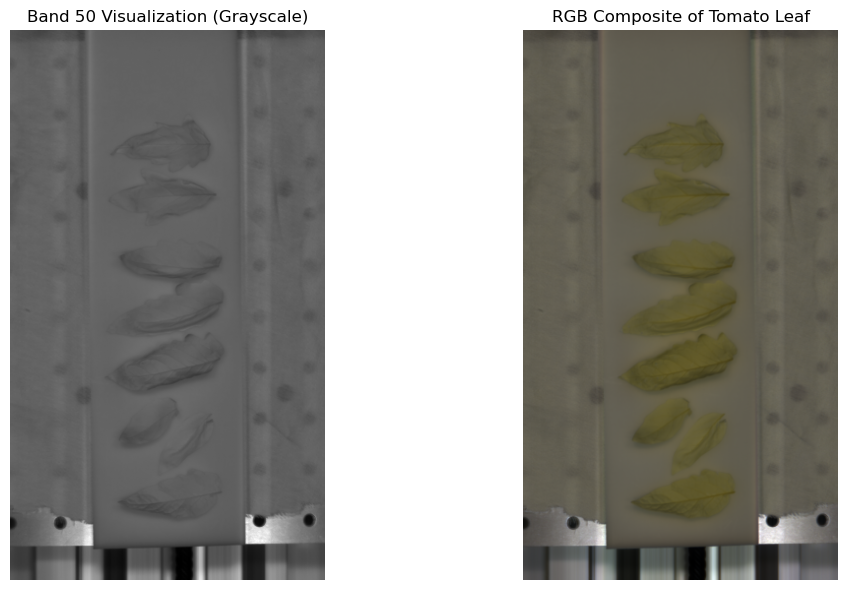

In [8]:
# Single band (grayscale) visualization
band_idx = 50
gray_img = data[:, :, band_idx]

# RGB composite (using bands 60=R, 30=G, 10=B)
rgb = sp.get_rgb(img, [50, 80, 130])

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Left: grayscale band
axes[0].imshow(gray_img, cmap="gray")
axes[0].set_title(f"Band {band_idx} Visualization (Grayscale)")
axes[0].axis("off")

# Right: RGB composite
axes[1].imshow(rgb)
axes[1].set_title("RGB Composite of Tomato Leaf")
axes[1].axis("off")

plt.tight_layout()
plt.show()


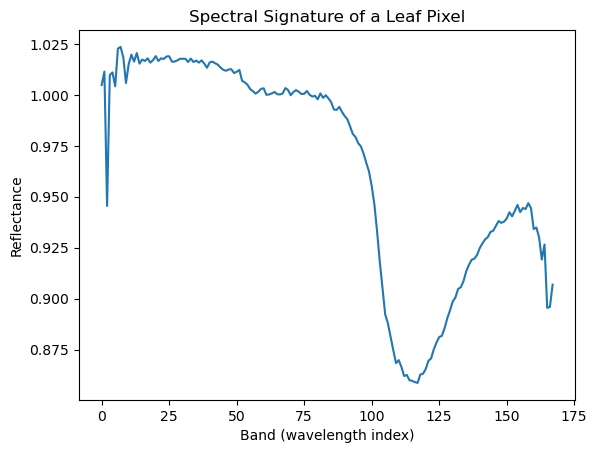

In [5]:
# Pick pixel coordinates
x, y = 200, 150

# Extract spectral signature
spectrum = data[x, y, :]    # shape (1, 1, 168) sometimes
spectrum = np.squeeze(spectrum)   # now shape (168,)

# Plot spectral signature
plt.plot(spectrum)
plt.title("Spectral Signature of a Leaf Pixel")
plt.xlabel("Band (wavelength index)")
plt.ylabel("Reflectance")
plt.show()


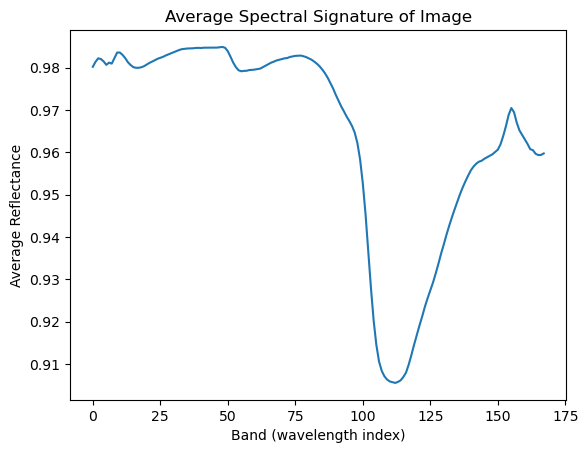

In [6]:
mean_spectrum = np.mean(data.reshape(-1, data.shape[-1]), axis=0)

plt.plot(mean_spectrum)
plt.title("Average Spectral Signature of Image")
plt.xlabel("Band (wavelength index)")
plt.ylabel("Average Reflectance")
plt.show()


In [9]:
import glob
import spectral as sp

# Load all .bil files
file_list = glob.glob("tomato_leaf/*.bil")
print(f"Total files found: {len(file_list)}")


Total files found: 65


In [12]:
import os
import spectral as sp
import numpy as np

folder = "tomato_leaf"
file_list = [os.path.join(folder, f) for f in os.listdir(folder) if f.endswith(".bil.hdr")]

all_shapes = []
all_means = []

for hdr_file in file_list:
    img = sp.open_image(hdr_file)   # Open using the .bil.hdr file
    data = img.load()
    
    # Save shape info
    all_shapes.append(data.shape)
    
    # Mean reflectance spectrum for each image
    mean_spectrum = np.mean(data, axis=(0,1))
    all_means.append(mean_spectrum)

print("Total images processed:", len(all_means))
print("Shapes of images:", set(all_shapes))  # should all be same


Total images processed: 65
Shapes of images: {(400, 900, 300), (500, 900, 300), (509, 320, 168), (1500, 900, 300), (607, 320, 168), (1199, 900, 300), (470, 320, 168), (569, 320, 168), (642, 320, 168), (1433, 900, 300), (644, 320, 168), (582, 320, 168), (541, 320, 168), (407, 320, 168), (650, 320, 168), (469, 320, 168), (663, 320, 168), (295, 320, 168), (588, 320, 168), (678, 320, 168), (538, 320, 168), (665, 320, 168), (612, 320, 168), (1592, 900, 300), (1200, 900, 300), (301, 320, 168), (600, 900, 300), (615, 320, 168), (302, 320, 168), (565, 320, 168), (900, 900, 300), (575, 320, 168), (598, 320, 168), (799, 900, 300), (586, 320, 168), (1700, 900, 300), (661, 320, 168), (309, 320, 168), (800, 900, 300), (674, 320, 168), (1158, 900, 300), (339, 320, 168), (559, 320, 168), (447, 320, 168)}


In [14]:
for i, m in enumerate(all_means):
    print(f"Image {i} mean spectrum length: {len(m)}")


Image 0 mean spectrum length: 168
Image 1 mean spectrum length: 168
Image 2 mean spectrum length: 168
Image 3 mean spectrum length: 300
Image 4 mean spectrum length: 300
Image 5 mean spectrum length: 168
Image 6 mean spectrum length: 168
Image 7 mean spectrum length: 168
Image 8 mean spectrum length: 300
Image 9 mean spectrum length: 300
Image 10 mean spectrum length: 300
Image 11 mean spectrum length: 168
Image 12 mean spectrum length: 168
Image 13 mean spectrum length: 300
Image 14 mean spectrum length: 300
Image 15 mean spectrum length: 168
Image 16 mean spectrum length: 168
Image 17 mean spectrum length: 300
Image 18 mean spectrum length: 300
Image 19 mean spectrum length: 168
Image 20 mean spectrum length: 168
Image 21 mean spectrum length: 300
Image 22 mean spectrum length: 300
Image 23 mean spectrum length: 300
Image 24 mean spectrum length: 168
Image 25 mean spectrum length: 168
Image 26 mean spectrum length: 168
Image 27 mean spectrum length: 300
Image 28 mean spectrum length:

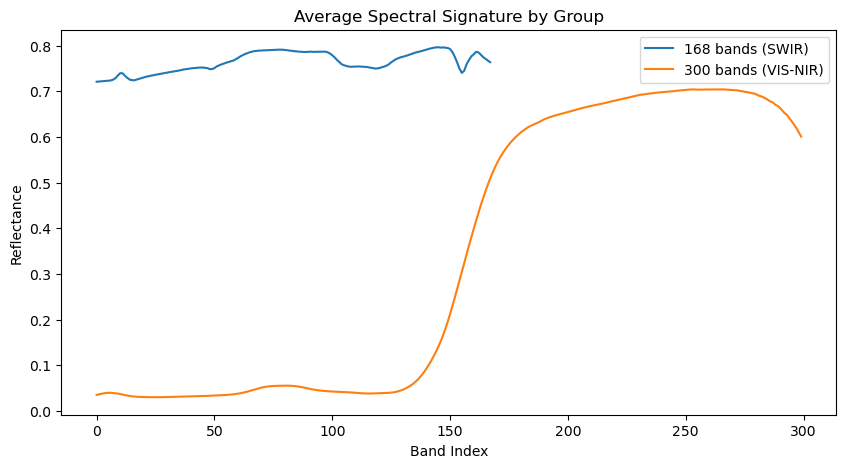

In [15]:
# Separate by number of bands
group_168 = [m for m in all_means if len(m)==168]
group_300 = [m for m in all_means if len(m)==300]

# Compute average spectrum per group
avg_168 = np.mean(group_168, axis=0)
avg_300 = np.mean(group_300, axis=0)

# Plot
plt.figure(figsize=(10,5))
plt.plot(avg_168, label="168 bands (SWIR)")
plt.plot(avg_300, label="300 bands (VIS-NIR)")
plt.title("Average Spectral Signature by Group")
plt.xlabel("Band Index")
plt.ylabel("Reflectance")
plt.legend()
plt.show()


Found 65 .bil.hdr files.
Number of 168-band images: 32
Number of 300-band images: 33
Unique shapes in dataset: {(400, 900, 300), (500, 900, 300), (509, 320, 168), (1500, 900, 300), (607, 320, 168), (1199, 900, 300), (470, 320, 168), (569, 320, 168), (642, 320, 168), (1433, 900, 300), (644, 320, 168), (582, 320, 168), (541, 320, 168), (407, 320, 168), (650, 320, 168), (469, 320, 168), (663, 320, 168), (295, 320, 168), (588, 320, 168), (678, 320, 168), (538, 320, 168), (665, 320, 168), (612, 320, 168), (1592, 900, 300), (1200, 900, 300), (301, 320, 168), (600, 900, 300), (615, 320, 168), (302, 320, 168), (565, 320, 168), (900, 900, 300), (575, 320, 168), (598, 320, 168), (799, 900, 300), (586, 320, 168), (1700, 900, 300), (661, 320, 168), (309, 320, 168), (800, 900, 300), (674, 320, 168), (1158, 900, 300), (339, 320, 168), (559, 320, 168), (447, 320, 168)}


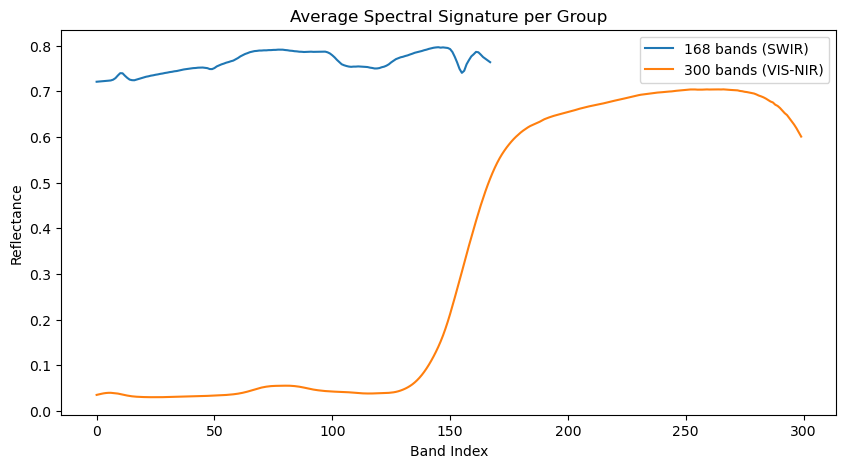

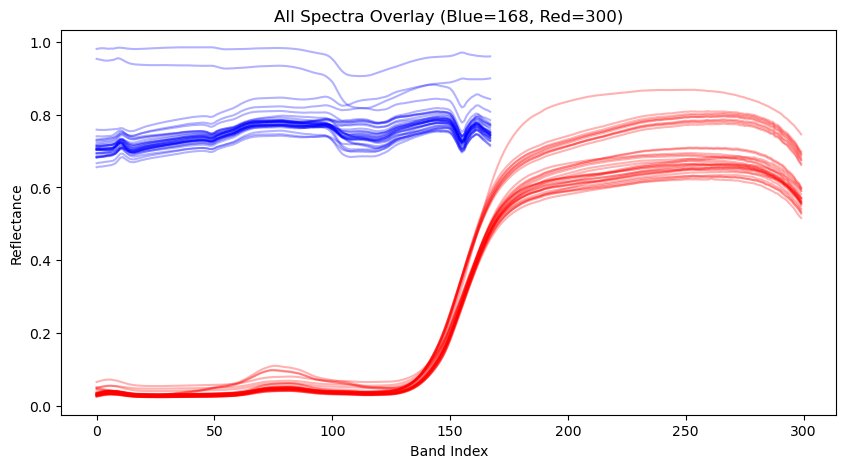

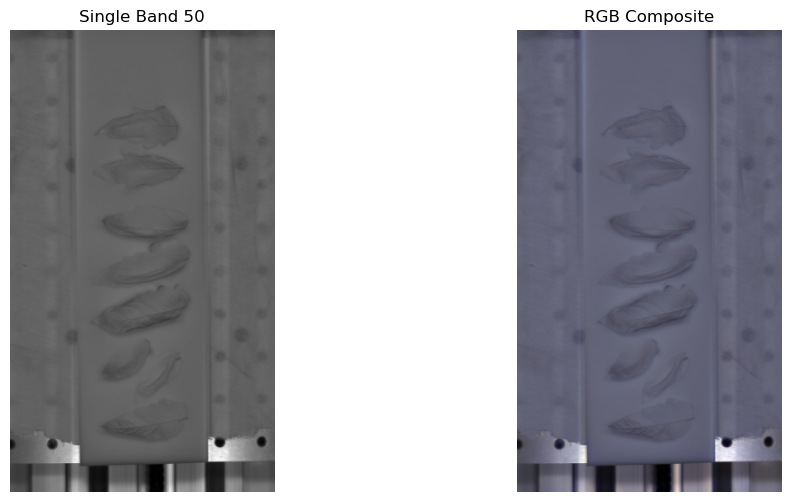

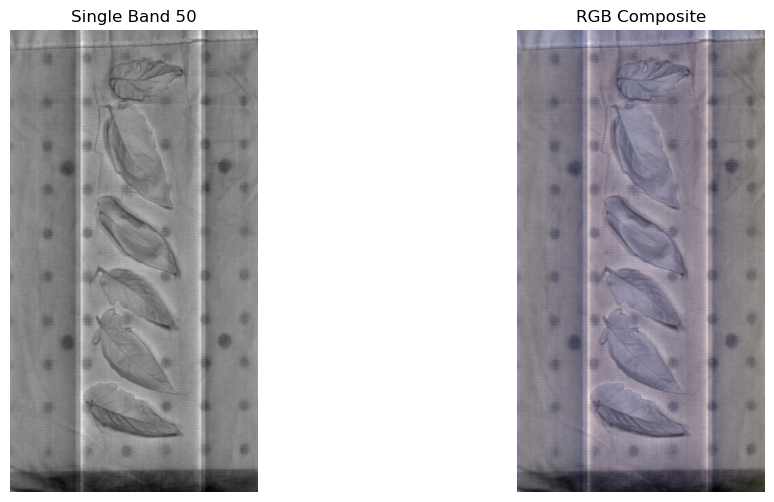

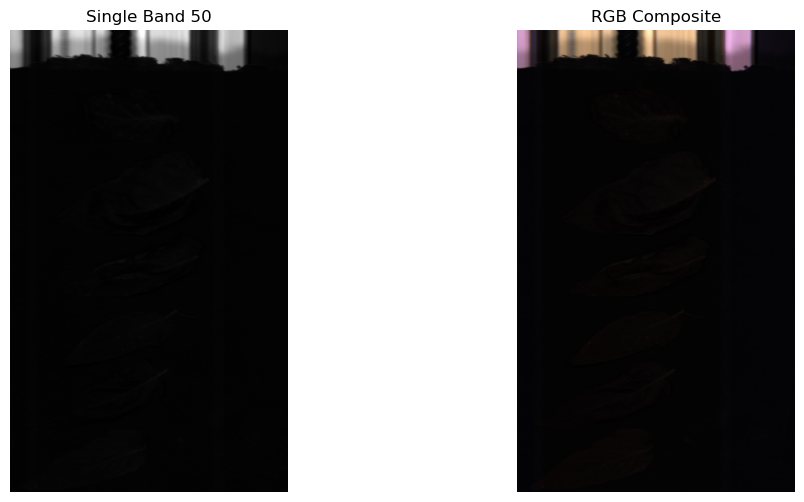

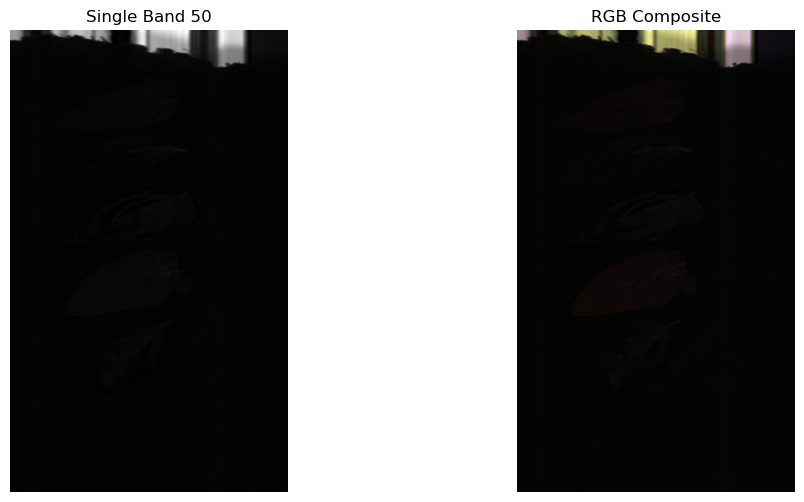

=== Pixel Stats for 168-band (SWIR) ===
Mean per band: [0.84784734] ...
Min per band: [0.0383] ...
Max per band: [3.0836] ...

=== Pixel Stats for 300-band (VIS-NIR) ===
Mean per band: [0.33637238] ...
Min per band: [0.] ...
Max per band: [2.2265] ...



In [16]:
import os
import glob
import spectral as sp
import numpy as np
import matplotlib.pyplot as plt

# Folder with your images
folder = "tomato_leaf"
hdr_files = glob.glob(os.path.join(folder, "*.bil.hdr"))
print(f"Found {len(hdr_files)} .bil.hdr files.")

# Initialize lists
all_shapes = []
all_means_168 = []
all_means_300 = []

# Loop through files
for hdr_file in hdr_files:
    img = sp.open_image(hdr_file)
    data = img.load()
    all_shapes.append(data.shape)
    
    mean_spectrum = np.mean(data, axis=(0,1))  # mean across pixels
    
    if len(mean_spectrum) == 168:
        all_means_168.append(mean_spectrum)
    elif len(mean_spectrum) == 300:
        all_means_300.append(mean_spectrum)

print("Number of 168-band images:", len(all_means_168))
print("Number of 300-band images:", len(all_means_300))
print("Unique shapes in dataset:", set(all_shapes))

# =======================
# 1. Plot average spectra for each group
# =======================
plt.figure(figsize=(10,5))
if all_means_168:
    avg_168 = np.mean(all_means_168, axis=0)
    plt.plot(avg_168, label="168 bands (SWIR)")
if all_means_300:
    avg_300 = np.mean(all_means_300, axis=0)
    plt.plot(avg_300, label="300 bands (VIS-NIR)")
plt.title("Average Spectral Signature per Group")
plt.xlabel("Band Index")
plt.ylabel("Reflectance")
plt.legend()
plt.show()

# =======================
# 2. Overlay all spectra (for variability check)
# =======================
plt.figure(figsize=(10,5))
for spec in all_means_168:
    plt.plot(spec, color='blue', alpha=0.3)
for spec in all_means_300:
    plt.plot(spec, color='red', alpha=0.3)
plt.title("All Spectra Overlay (Blue=168, Red=300)")
plt.xlabel("Band Index")
plt.ylabel("Reflectance")
plt.show()

# =======================
# 3. Show RGB and single-band visuals for a few images
# =======================
# Select first 2 images from each group
sample_files_168 = [f for f in hdr_files if sp.open_image(f).load().shape[2]==168][:2]
sample_files_300 = [f for f in hdr_files if sp.open_image(f).load().shape[2]==300][:2]

def show_rgb_and_band(file, band_idx=50):
    img = sp.open_image(file)
    data = img.load()
    
    # RGB composite (example bands for 300-band: 60=R, 30=G, 10=B)
    if data.shape[2] >= 60:
        rgb_bands = [60,30,10] if data.shape[2]==300 else [50,30,10]
        rgb = sp.get_rgb(img, rgb_bands)
    else:
        rgb = np.stack([data[:,:,0]]*3, axis=-1)
    
    gray = data[:,:,band_idx] if data.shape[2]>band_idx else data[:,:,0]
    
    fig, axes = plt.subplots(1,2, figsize=(12,6))
    axes[0].imshow(gray, cmap="gray")
    axes[0].set_title(f"Single Band {band_idx}")
    axes[0].axis("off")
    axes[1].imshow(rgb)
    axes[1].set_title("RGB Composite")
    axes[1].axis("off")
    plt.show()

# Show sample visuals
for f in sample_files_168 + sample_files_300:
    show_rgb_and_band(f)

# =======================
# 4. Pixel statistics summary
# =======================
def pixel_stats(group, name):
    all_pixels = np.concatenate([d.reshape(-1, len(d[0,0,:])) for d in group], axis=0)
    mean_val = np.mean(all_pixels, axis=0)
    min_val = np.min(all_pixels, axis=0)
    max_val = np.max(all_pixels, axis=0)
    print(f"=== Pixel Stats for {name} ===")
    print("Mean per band:", mean_val[:10], "...")  # print first 10 bands
    print("Min per band:", min_val[:10], "...")
    print("Max per band:", max_val[:10], "...\n")

# Load data for pixel stats
group_168_data = [sp.open_image(f).load() for f in sample_files_168]
group_300_data = [sp.open_image(f).load() for f in sample_files_300]

pixel_stats(group_168_data, "168-band (SWIR)")
pixel_stats(group_300_data, "300-band (VIS-NIR)")
